In [1]:
import pandas as pd
import seaborn as sns
from sentence_transformers import SentenceTransformer
embedding = SentenceTransformer('sentence-transformers/bert-base-nli-mean-tokens')

c:\Users\lucie\OneDrive\Documents\TrustCalibration\FGW\.venv3\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3249.32it/s]


In [2]:
data = pd.read_csv('../data_with_text_tag\generated_instructions_with_intention_explanation_full_ability_gender_woman_gpt.csv')

In [3]:
data.head()

,instruction_id,generated_id,ability,instruction_with_intention,instruction
0,0,0_0_2,High,{f: confidence} [thoughtful] {t: Positive.Emot...,The exist sign shows left you advise to take t...
1,0,0_0_2,High,{f: confidence} [clear {t: Positive.Emotion} ...,The exist sign shows left you advise to take t...
2,0,0_0_1,Medium,{f: confidence}{g: Arm Gesture (Left)}[thought...,The exist sign shows left you advise to take t...
3,0,0_0_0,Low,"{f: scared} [uncertain] {t: Hedges, Negative.E...",The exist sign shows left you advise to take t...
4,0,0_0_0,Low,{f: confused} [short pause] {g: Arm Gesture (L...,The exist sign shows left you advise to take t...


In [4]:
embedded_text = embedding.encode(data['instruction_with_intention'].tolist(), show_progress_bar=True)

Batches: 100%|██████████| 63/63 [02:12<00:00,  2.10s/it]


In [5]:
def k_means_clustering(embedded_text, n_clusters=3):
    from sklearn.cluster import KMeans
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(embedded_text)
    return kmeans.labels_

In [6]:
data['cluster'] = k_means_clustering(embedded_text, n_clusters=3)

<Axes: xlabel='cluster', ylabel='Count'>

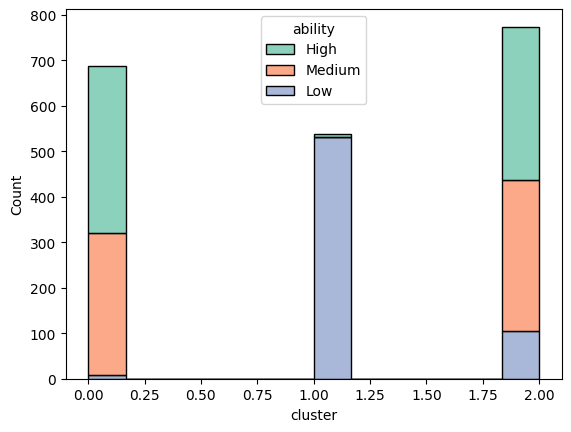

In [7]:
sns.histplot(x='cluster', data=data, hue='ability', multiple='stack', palette='Set2')